# CLEARS — Exploratory Data Analysis (v2)
**File:** `notebooks/01_eda_v2.ipynb`  |  **Author:** Person 1 — Data & Analytics Lead
**Dataset:** `features_final_v2.csv` (same 38 columns as v1; only the four rolling features were rebuilt, see `feature_dictionary_v2.md`)
**Airports:** ORD (Chicago O'Hare) | MEM (Memphis International)  |  **Period:** Jan 2019 – Oct 2022, **months Jan / Apr / Jul / Oct only**

This notebook replaces the v1 notebook, whose plotting cells contained only a title comment (the code had not been saved). Every chart below is generated by the code in this notebook. Several v1 text findings were wrong and are corrected here (marked **corrected**).

## 1. Dataset overview

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
CANDIDATES = [Path('../features_final_v2.csv'), Path('features_final_v2.csv'),
              Path('../data/processed/features_final_v2.csv')]
DATA = next(p for p in CANDIDATES if p.exists())
ASSETS = Path('../assets') if Path('../assets').exists() else Path('assets')
ASSETS.mkdir(exist_ok=True)
COLORS = {'ORD': '#D85A30', 'MEM': '#1D9E75'}

df = pd.read_csv(DATA, low_memory=False, parse_dates=['timestamp', 'flight_date'])
print('File:', DATA.name, '| shape:', df.shape)
print('\nRecords per airport:\n', df['airport_code'].value_counts().to_string())
print('\nDate range:', df['flight_date'].min().date(), 'to', df['flight_date'].max().date())
print('Distinct dates with data:', df['flight_date'].nunique(), '(calendar span is',
      (df['flight_date'].max() - df['flight_date'].min()).days + 1, 'days)')
print('Months present:', sorted(df['month'].unique()))
print('\nOverall disruption rate: %.2f%%' % (df['disruption'].mean() * 100))
print('Null cells in the whole matrix:', int(df.isnull().sum().sum()))

File: features_final_v2.csv | shape: (370729, 38)

Records per airport:
 airport_code
ORD    341399
MEM     29330

Date range: 2019-01-01 to 2022-10-31
Distinct dates with data: 492 (calendar span is 1400 days)
Months present: [1, 4, 7, 10]

Overall disruption rate: 17.86%
Null cells in the whole matrix: 0


**Key facts.** 370,729 flight departures (ORD 341,399; MEM 29,330). Data exists for only 492 distinct dates because BTS data was downloaded for January, April, July and October only — about 35% of the calendar span, so results say little about November–December or spring/autumn shoulder months. Zero null cells.

## 2. Disruption rate by airport

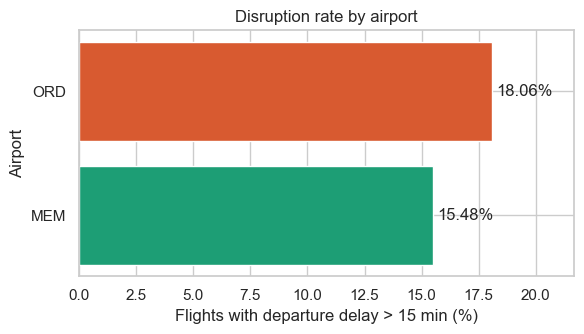

In [2]:
rate = df.groupby('airport_code')['disruption'].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(rate.index, rate.values, color=[COLORS[a] for a in rate.index])
for y, v in enumerate(rate.values):
    ax.text(v + 0.2, y, f'{v:.2f}%', va='center')
ax.set_xlabel('Flights with departure delay > 15 min (%)')
ax.set_ylabel('Airport')
ax.set_title('Disruption rate by airport')
ax.set_xlim(0, rate.max() * 1.2)
plt.tight_layout(); plt.show()

**Finding.** ORD 18.06% vs MEM 15.48% (overall 17.86%). ORD has 341,399 flights vs 29,330 for MEM (**corrected** — v1 text said 356,828). The class ratio is about 4.6 : 1, so `scale_pos_weight ≈ 4.6` is needed in XGBoost.

## 3. Distribution of weather variables

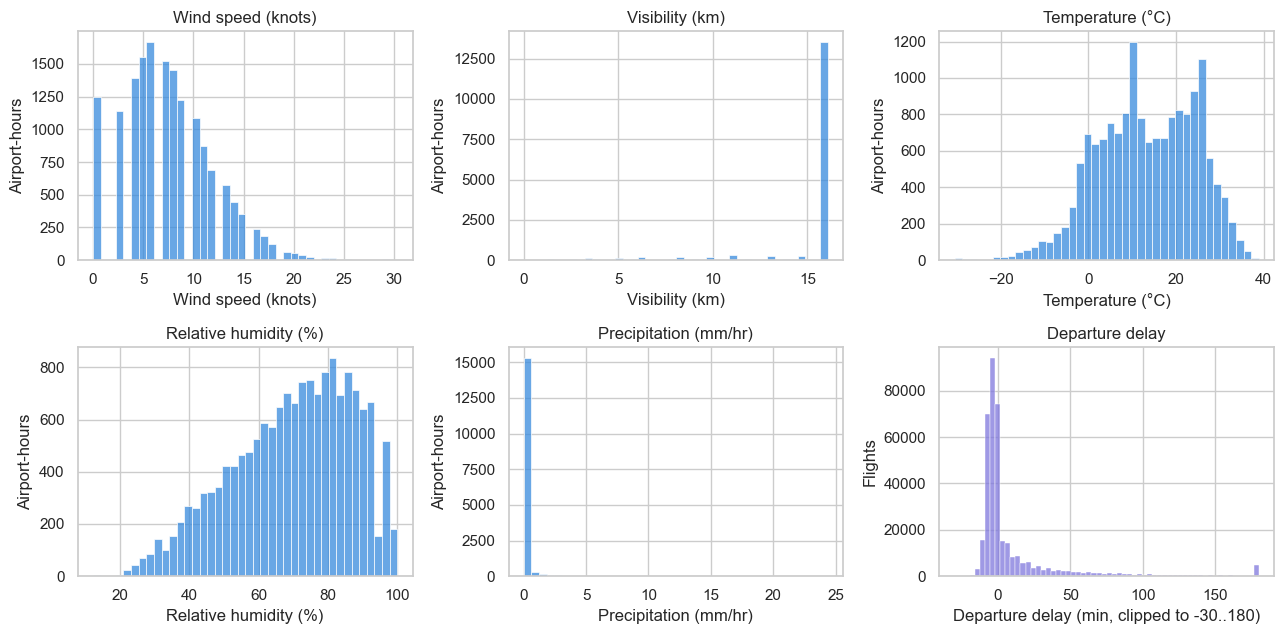

Max wind: 30.3 kn | visibility < 3 km: 1.76% of flights | no precipitation: 90.2% of flights


In [3]:
wx = df.drop_duplicates(['airport_code', 'timestamp'])      # one row per airport-hour, not per flight
panels = [('wind_speed_knots', 'Wind speed (knots)'), ('visibility_km', 'Visibility (km)'),
          ('temperature_c', 'Temperature (°C)'), ('humidity_pct', 'Relative humidity (%)'),
          ('precip_mm_hr', 'Precipitation (mm/hr)')]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, label) in zip(axes.ravel(), panels):
    sns.histplot(wx[col], bins=40, color='#378ADD', ax=ax)
    ax.set_xlabel(label); ax.set_ylabel('Airport-hours'); ax.set_title(label)
sns.histplot(df['dep_delay'].clip(-30, 180), bins=60, color='#7F77DD', ax=axes[1, 2])
axes[1, 2].set_xlabel('Departure delay (min, clipped to -30..180)'); axes[1, 2].set_ylabel('Flights')
axes[1, 2].set_title('Departure delay')
plt.tight_layout(); plt.show()
print('Max wind: %.1f kn | visibility < 3 km: %.2f%% of flights | no precipitation: %.1f%% of flights'
      % (df['wind_speed_knots'].max(), df['visibility_risk'].mean() * 100, (df['precip_mm_hr'] == 0).mean() * 100))

**Findings.** Wind is right-skewed and never exceeds 30.3 knots, so the `severe` wind category and the wind > 50 kn part of `storm_flag` never occur. Visibility is capped at 16.09 km (10 miles) with a small low-visibility tail. Precipitation is zero for ~90% of flights. Departure delay has a long right tail (capped at 300 for `delay_minutes`).

## 4. Disruption rate by hour of day

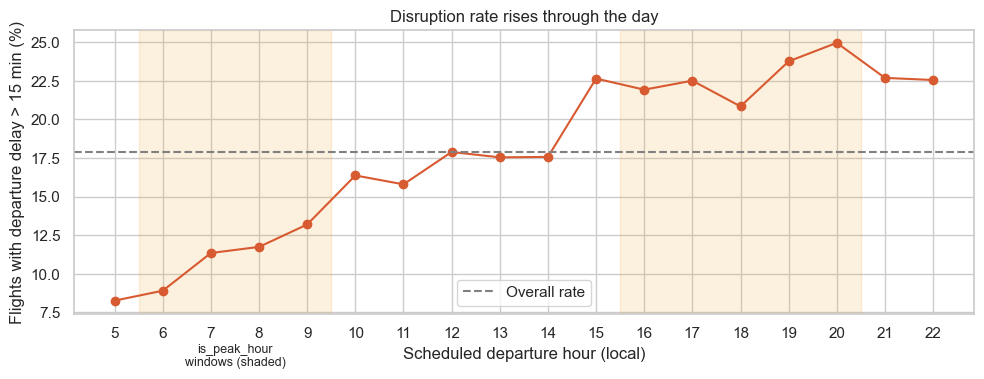

Disruption rate: peak 17.59% vs off-peak 18.23% (ratio 0.97)


In [4]:
hourly = df.groupby('hour_of_day')['disruption'].agg(['mean', 'size'])
hourly = hourly[hourly['size'] >= 500]              # hours 0, 1, 23 have too few flights to read
fig, ax = plt.subplots(figsize=(10, 4))
for a, b in [(6, 9), (16, 20)]:
    ax.axvspan(a - 0.5, b + 0.5, color='#EF9F27', alpha=0.15)
ax.plot(hourly.index, hourly['mean'] * 100, marker='o', color='#D85A30')
ax.axhline(df['disruption'].mean() * 100, ls='--', color='grey', label='Overall rate')
ax.text(7.5, 4, "is_peak_hour\nwindows (shaded)", ha='center', fontsize=9)
ax.set_xlabel('Scheduled departure hour (local)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Disruption rate rises through the day')
ax.set_xticks(hourly.index); ax.legend()
plt.tight_layout()
plt.savefig(ASSETS / 'eda_key_chart.png', dpi=150, bbox_inches='tight')    # key chart for the presentation
plt.show()
peak = df.groupby('is_peak_hour')['disruption'].mean() * 100
print('Disruption rate: peak %.2f%% vs off-peak %.2f%% (ratio %.2f)' % (peak[1], peak[0], peak[1] / peak[0]))

**Finding (corrected).** Disruption rises through the day — about 8% at 05:00, 16–18% around noon, and roughly 21–25% between 15:00 and 22:00 — consistent with delays accumulating and cascading. The `is_peak_hour` flag (06–09 and 16–20) does **not** capture this: peak 17.59% vs off-peak 18.23%, ratio ≈ 0.97, because 06–09 is the lowest-risk period. Use `hour_of_day`; `is_peak_hour` is not validated by the data (v1 text claimed it was).

## 5. Disruption rate by day of week

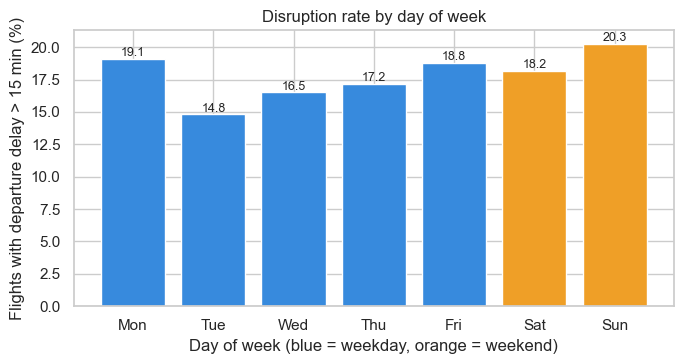

is_weekend
weekday    17.33
weekend    19.29


In [5]:
dow = df.groupby('day_of_week')['disruption'].mean().mul(100)
labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(labels, dow.values, color=['#378ADD'] * 5 + ['#EF9F27'] * 2)
for i, v in enumerate(dow.values):
    ax.text(i, v + 0.2, f'{v:.1f}', ha='center', fontsize=9)
ax.set_xlabel('Day of week (blue = weekday, orange = weekend)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Disruption rate by day of week')
plt.tight_layout(); plt.show()
print(df.groupby('is_weekend')['disruption'].mean().mul(100).round(2).rename({0: 'weekday', 1: 'weekend'}).to_string())

**Finding (corrected).** Sunday is highest (20.3%), then Monday (19.1%) and Friday (18.8%); Tuesday is lowest (14.8%). Weekends overall are *higher* than weekdays (19.3% vs 17.3%) — v1 said weekend disruption was lower.

## 6. Hour × day-of-week heatmap

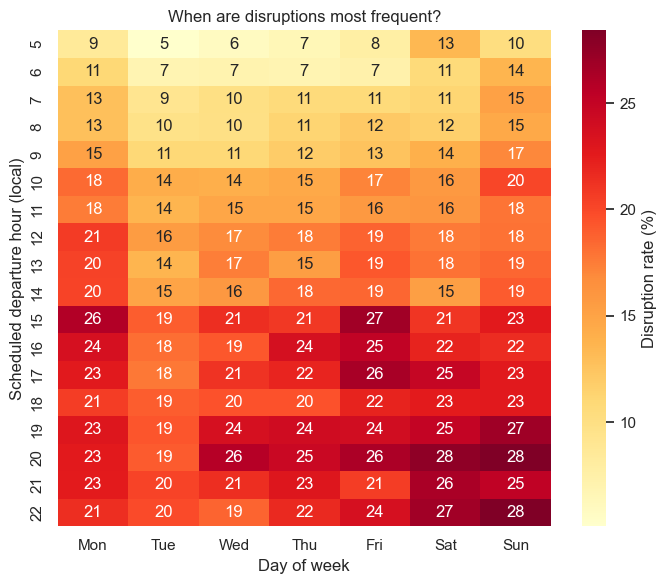

In [6]:
pivot = (df[df['hour_of_day'].between(5, 22)]
         .pivot_table(index='hour_of_day', columns='day_of_week', values='disruption', aggfunc='mean') * 100)
pivot.columns = labels
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'Disruption rate (%)'}, ax=ax)
ax.set_xlabel('Day of week'); ax.set_ylabel('Scheduled departure hour (local)')
ax.set_title('When are disruptions most frequent?')
plt.tight_layout(); plt.show()

**Finding.** Late-afternoon and evening hours are the high-risk cells on every day of the week; early-morning departures are consistently the lowest.

## 7. Monthly disruption trend — ORD vs MEM

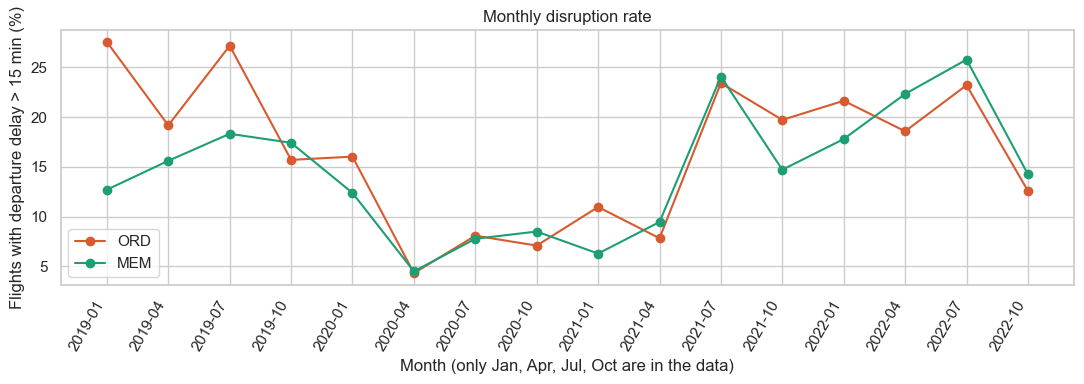

By year (%): {2019: 21.7, 2020: 10.5, 2021: 17.0, 2022: 19.0}
By month (%): {1: 19.5, 4: 14.8, 7: 22.0, 10: 14.7}


In [7]:
ym = (df.assign(period=df['flight_date'].dt.to_period('M').astype(str))
        .groupby(['period', 'airport_code'])['disruption'].mean().mul(100).unstack())
fig, ax = plt.subplots(figsize=(11, 4))
for a in ['ORD', 'MEM']:
    ax.plot(range(len(ym)), ym[a], marker='o', color=COLORS[a], label=a)
ax.set_xticks(range(len(ym))); ax.set_xticklabels(ym.index, rotation=60, ha='right')
ax.set_xlabel('Month (only Jan, Apr, Jul, Oct are in the data)')
ax.set_ylabel('Flights with departure delay > 15 min (%)')
ax.set_title('Monthly disruption rate'); ax.legend()
plt.tight_layout(); plt.show()
print('By year (%):', (df.groupby(df['flight_date'].dt.year)['disruption'].mean() * 100).round(1).to_dict())
print('By month (%):', (df.groupby('month')['disruption'].mean() * 100).round(1).to_dict())

**Findings.** July (22.0%) and January (19.5%) are the highest-risk months; April and October are about 14.7%. 2020 is an anomaly (10.5% vs 17–22% in other years — far fewer flights during COVID-19), so the model sees one very different regime. ORD is above MEM in only 8 of the 16 months, and **MEM is higher than ORD in every 2022 month** (Apr 22.3% vs 18.6%, Jul 25.8% vs 23.2%, Oct 14.2% vs 12.6%) -- i.e. throughout the period that will be used as the test set. The airport ranking is not stable over time, which also weakens the ORD-vs-MEM resilience comparison.

## 8. Weather-event frequency by airport

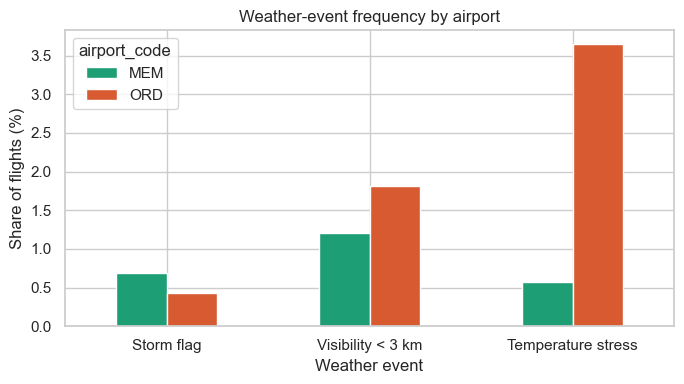

              Storm flag  Visibility < 3 km  Temperature stress
airport_code                                                   
MEM                 0.69               1.21                0.58
ORD                 0.43               1.81                3.64


In [8]:
events = (df.groupby('airport_code')[['storm_flag', 'visibility_risk', 'temp_stress']].mean().mul(100)
            .rename(columns={'storm_flag': 'Storm flag', 'visibility_risk': 'Visibility < 3 km',
                             'temp_stress': 'Temperature stress'}))
ax = events.T.plot.bar(figsize=(7, 4), color=[COLORS['MEM'], COLORS['ORD']], rot=0)
ax.set_xlabel('Weather event'); ax.set_ylabel('Share of flights (%)')
ax.set_title('Weather-event frequency by airport')
plt.tight_layout(); plt.show()
print(events.round(2).to_string())

**Finding (corrected).** ORD has more low-visibility flights (1.81% vs 1.21%) and far more temperature stress (3.64% vs 0.58%), but MEM has the *higher* storm-flag rate (0.69% vs 0.43%); v1 said ORD was higher on storm flag. Storm flag is rare (0.45% overall) and fires only on visibility < 1 km or heavy rain.

## 9. Correlation with disruption

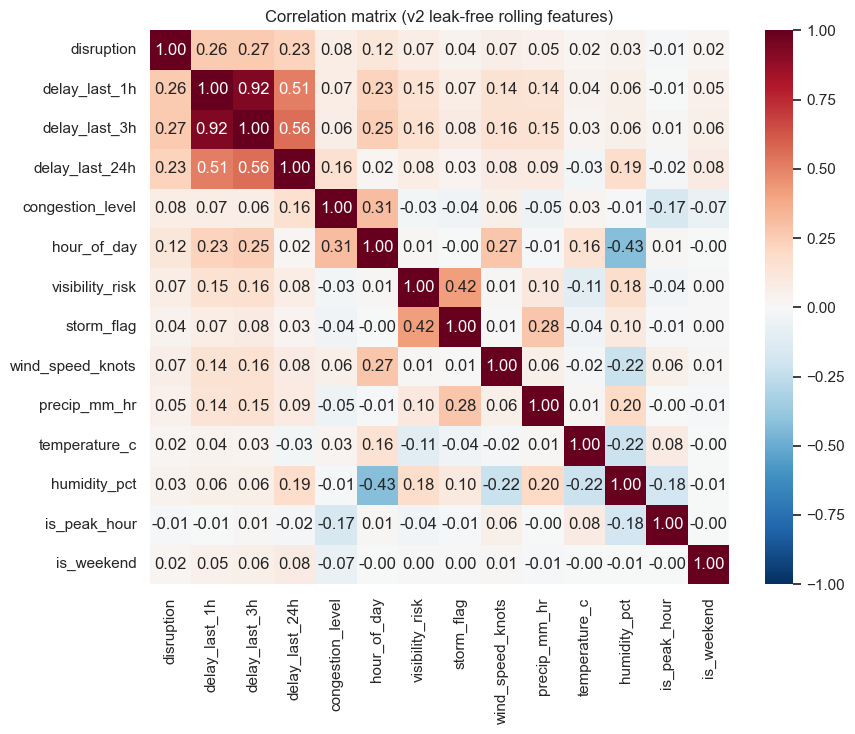

delay_last_3h       0.2651
delay_last_1h       0.2623
delay_last_24h      0.2270
hour_of_day         0.1193
congestion_level    0.0756
visibility_risk     0.0745
wind_speed_knots    0.0697
precip_mm_hr        0.0531
storm_flag          0.0383
humidity_pct        0.0344
is_weekend          0.0227
temperature_c       0.0187
is_peak_hour       -0.0082


In [9]:
cols = ['disruption', 'delay_last_1h', 'delay_last_3h', 'delay_last_24h', 'congestion_level', 'hour_of_day',
        'visibility_risk', 'storm_flag', 'wind_speed_knots', 'precip_mm_hr', 'temperature_c', 'humidity_pct',
        'is_peak_hour', 'is_weekend']
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation matrix (v2 leak-free rolling features)')
plt.tight_layout(); plt.show()
print(corr['disruption'].drop('disruption').sort_values(ascending=False).round(4).to_string())

**Findings.** The strongest linear signals are the rolling disruption rates: `delay_last_3h` 0.265, `delay_last_1h` 0.262, `delay_last_24h` 0.227 — disruptions cascade. These are lower than the v1 values (0.347 / 0.302 / 0.254), which were inflated by outcomes of same-hour flights. `hour_of_day` (0.12) is the next strongest; `visibility_risk` 0.07 and `storm_flag` 0.04 are weak; `is_peak_hour` is ≈ 0. Single weather variables correlate below 0.08 with disruption, so the F1 ≥ 0.70 target is an open question, not an assumption.

## 10. Diagnostic: is the weather aligned with departure time?

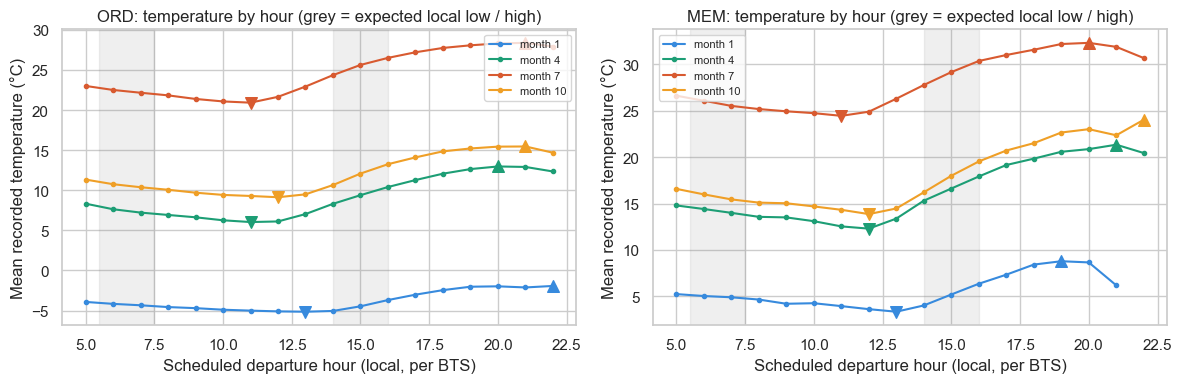

                    hour of lowest temperature  hour of highest temperature
airport_code month                                                         
MEM          1                              13                           19
             4                              12                           21
             7                              11                           20
             10                             12                           22
ORD          1                              13                           22
             4                              11                           20
             7                              11                           21
             10                             12                           21


In [10]:
wx = df.drop_duplicates(['airport_code', 'timestamp'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, a in zip(axes, ['ORD', 'MEM']):
    for m, c in zip([1, 4, 7, 10], ['#378ADD', '#1D9E75', '#D85A30', '#EF9F27']):
        s = wx[(wx['airport_code'] == a) & (wx['month'] == m) & wx['hour_of_day'].between(5, 22)]
        s = s.groupby('hour_of_day')['temperature_c'].mean()
        ax.plot(s.index, s.values, marker='o', ms=3, color=c, label=f'month {m}')
        ax.scatter([s.idxmin()], [s.min()], marker='v', s=70, color=c)
        ax.scatter([s.idxmax()], [s.max()], marker='^', s=70, color=c)
    ax.axvspan(5.5, 7.5, color='grey', alpha=0.12)
    ax.axvspan(14, 16, color='grey', alpha=0.12)
    ax.set_xlabel('Scheduled departure hour (local, per BTS)')
    ax.set_ylabel('Mean recorded temperature (°C)')
    ax.set_title(f'{a}: temperature by hour (grey = expected local low / high)')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
t = wx[wx['hour_of_day'].between(5, 22)].groupby(['airport_code', 'month', 'hour_of_day'])['temperature_c'].mean()
low = t.groupby(['airport_code', 'month']).idxmin().map(lambda i: i[2])
high = t.groupby(['airport_code', 'month']).idxmax().map(lambda i: i[2])
print(pd.DataFrame({'hour of lowest temperature': low, 'hour of highest temperature': high}).to_string())

**Finding (data problem).** In every month and at both airports, mean temperature is lowest around hours 11–13 and highest around 19–22; a correct local-time series would have its minimum near 06:00 and maximum near 15:00. The ~5–6 h offset matches NOAA ISD times (UTC) being merged onto BTS local times without conversion. The weather columns therefore describe conditions about 5–6 hours **before** the scheduled departure. `src/data_prep.py` (v2) converts to `America/Chicago` before merging, but the raw data must be re-run to regenerate the dataset; until then all weather-based conclusions in this notebook are provisional.

## 11. Key EDA conclusions (v2)

| Insight | Implication for the model |
|---|---|
| ORD 18.1% vs MEM 15.5% disruption; overall 17.9% (≈ 4.6 : 1) | Use `scale_pos_weight ≈ 4.6`; report metrics per airport |
| Rolling disruption rates are the strongest signals (corr ≈ 0.23–0.27, leak-free) | Keep them, use only the v2 versions |
| Disruption rises through the day; `is_peak_hour` shows no premium (ratio 0.97) | Use `hour_of_day`; do not rely on `is_peak_hour` |
| July (22.0%) and January (19.5%) highest; April/October ≈ 14.7% | `month` is informative; `is_holiday_season` equals `month == 10` here (redundant) |
| Storm flag is rare (0.45%) and never fires on wind | Little signal from it; do not over-interpret SHAP for it |
| 2020 dip (10.5%) and no winter month in the 2022 test period | Evaluate per month; test metrics will not cover winter |
| Weather appears ~5–6 h out of sync with departure hours | Fix `data_prep.py` and regenerate before final model conclusions |

**Overall.** The dataset is usable for supervised learning once the v2 rolling features are used, but weather-driven conclusions must wait for the timezone fix.